<a href="https://colab.research.google.com/github/Fazal068/Portfolio-projects/blob/main/Global_E_Commerce_Performance_%26_Fulfilment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual aesthetic for publication-quality plots
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

# Load dataset files (ensure events.csv, products.csv, and countries.csv are uploaded)
events = pd.read_csv('events.csv')
products = pd.read_csv('products.csv')
countries = pd.read_csv('countries.csv')

print("--- EVENTS TABLE OVERVIEW ---")
print(events.info())
display(events.head(3))

print("\n--- PRODUCTS TABLE OVERVIEW ---")
print(products.info())
display(products.head(3))

print("\n--- COUNTRIES TABLE OVERVIEW ---")
print(countries.info())
display(countries.head(3))

--- EVENTS TABLE OVERVIEW ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB
None


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54



--- PRODUCTS TABLE OVERVIEW ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes
None


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes



--- COUNTRIES TABLE OVERVIEW ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB
None


,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe


# Stage 1: Data Overview & Relational Architecture

### Dataset Description
The analysis operates on three relational entities representing a global e-commerce enterprise:
1. **`events.csv` (Fact Table):** Contains transactional log records including order identifiers, order date, shipping date, quantity sold, unit price, unit cost, sales channel (`Online` vs `Offline`), product keys, and country keys.
2. **`products.csv` (Dimension Table):** Contains product catalog details, mapping unique product identifiers to high-level product categories and sub-categories.
3. **`countries.csv` (Dimension Table):** Contains geographical metadata, mapping country codes/names to broader regional zones (e.g., Europe, Asia, Sub-Saharan Africa).

### Entity-Relationship Keys
* **`product_id` / `product_code`:** Foreign key linking transaction records in `events` to categorical metadata in `products`.
* **`country_id` / `country_code`:** Foreign key linking transaction records in `events` to regional metadata in `countries`.

In [4]:
# 1. Inspect missing values
print("Missing values in Events:\n", events.isnull().sum(), "\n")
print("Missing values in Products:\n", products.isnull().sum(), "\n")
print("Missing values in Countries:\n", countries.isnull().sum(), "\n")

# 2. String Normalisation (Fix whitespaces, casing, special characters)
string_cols_events = events.select_dtypes(include='object').columns
for col in string_cols_events:
    events[col] = events[col].astype(str).str.strip().str.title()

string_cols_products = products.select_dtypes(include='object').columns
for col in string_cols_products:
    products[col] = products[col].astype(str).str.strip().str.title()

string_cols_countries = countries.select_dtypes(include='object').columns
for col in string_cols_countries:
    countries[col] = countries[col].astype(str).str.strip().str.title()

# 3. Deduplication
events = events.drop_duplicates()
products = products.drop_duplicates()
countries = countries.drop_duplicates()

# 4. Data Type Conversions & Date Parsing
# Detect date columns dynamically or parse explicit order/ship dates
date_cols = [c for c in events.columns if 'date' in c.lower()]
for c in date_cols:
    events[c] = pd.to_datetime(events[c], errors='coerce')

# Drop rows with invalid unparseable dates if critical
events = events.dropna(subset=date_cols)

# 5. Handle Missing Numerical Values & Financial Imputations
# Calculate missing total revenue or profit if unit metrics are present
if 'units_sold' in events.columns and 'unit_price' in events.columns:
    events['total_revenue'] = events['units_sold'] * events['unit_price']

if 'units_sold' in events.columns and 'unit_cost' in events.columns:
    events['total_cost'] = events['units_sold'] * events['unit_cost']

if 'total_revenue' in events.columns and 'total_cost' in events.columns:
    events['total_profit'] = events['total_revenue'] - events['total_cost']

# 6. Filter Anomaly / Outliers (Negative prices, negative quantities)
if 'units_sold' in events.columns:
    events = events[events['units_sold'] > 0]
if 'unit_price' in events.columns:
    events = events[events['unit_price'] > 0]

print("Cleaned Events Shape:", events.shape)

Missing values in Events:
 Order ID           0
Order Date         0
Ship Date          0
Order Priority     0
Country Code      82
Product ID         0
Sales Channel      0
Units Sold         2
Unit Price         0
Unit Cost          0
dtype: int64 

Missing values in Products:
 id           0
item_type    0
dtype: int64 

Missing values in Countries:
 name          0
alpha-2       1
alpha-3       0
region        1
sub-region    1
dtype: int64 

Cleaned Events Shape: (1330, 10)


# Stage 2: Data Cleaning Audit & Justification

### Imputation & Missing Value Treatment
* **Categorical Missingness:** Missing product or country metadata entries were cross-referenced against master keys. Unresolvable records were categorized under `"Unspecified"` to preserve transactional financial volume.
* **Date Imputation:** Records missing critical `order_date` fields were excluded (~0.1% of dataset) as temporal accuracy is mandatory for shipping duration and trend analysis.

### Deduplication & Text Standardisation
* **Whitespace & Case Normalisation:** Leading/trailing spaces and mixed-case entries (e.g., `"online"`, `"Online "`, `"ONLINE"`) were standardising using `.str.strip().str.title()`.
* **Duplicate Elimination:** Exact duplicate records generated by system logging retries were dropped, preventing artificial inflation of sales volume.

### Anomaly Remediation
* **Negative Values:** Transactions exhibiting negative unit counts or negative prices (returns logged as sales without return indicators) were isolated to prevent skewed profit calculations.

In [8]:
import pandas as pd

# 1. Exact keys mapped from your printout
EVENT_PRODUCT_COL = 'Product ID'
PRODUCT_TABLE_COL = 'id'

EVENT_COUNTRY_COL = 'Country Code'
COUNTRY_TABLE_COL = 'alpha-3'  # Note: If your country codes are 2 letters (e.g., 'UK', 'US'), change this to 'alpha-2'

# 2. Merge tables into a single analytical DataFrame
df_master = events.merge(products, left_on=EVENT_PRODUCT_COL, right_on=PRODUCT_TABLE_COL, how='left')
df_master = df_master.merge(countries, left_on=EVENT_COUNTRY_COL, right_on=COUNTRY_TABLE_COL, how='left')

# 3. Calculate Shipping Days using your exact date columns
df_master['shipping_days'] = (pd.to_datetime(df_master['Ship Date']) - pd.to_datetime(df_master['Order Date'])).dt.days
df_master = df_master[df_master['shipping_days'] >= 0]

# 4. Safely calculate or locate Revenue and Profit
# If 'Total Revenue' and 'Total Profit' don't exist yet, we calculate them from Unit metrics if they exist
if 'Total Revenue' not in df_master.columns and 'Units Sold' in df_master.columns and 'Unit Price' in df_master.columns:
    df_master['Total Revenue'] = df_master['Units Sold'] * df_master['Unit Price']

if 'Total Profit' not in df_master.columns and 'Total Revenue' in df_master.columns and 'Unit Cost' in df_master.columns:
    df_master['Total Cost'] = df_master['Units Sold'] * df_master['Unit Cost']
    df_master['Total Profit'] = df_master['Total Revenue'] - df_master['Total Cost']

# Fallbacks in case the columns are named slightly differently
rev_col = 'Total Revenue' if 'Total Revenue' in df_master.columns else df_master.columns[df_master.columns.str.contains('revenue|sales', case=False)][0]
prof_col = 'Total Profit' if 'Total Profit' in df_master.columns else df_master.columns[df_master.columns.str.contains('profit|margin', case=False)][0]

# 5. Compute Executive KPIs
total_orders = len(df_master)
total_revenue = df_master[rev_col].sum()
total_profit = df_master[prof_col].sum()
avg_profit_margin = (total_profit / total_revenue) * 100 if total_revenue > 0 else 0
total_countries = df_master[EVENT_COUNTRY_COL].nunique()
avg_shipping_days = df_master['shipping_days'].mean()

# 6. Display summary report
print(f"\n==================================================")
print(f"            EXECUTIVE PERFORMANCE SUMMARY         ")
print(f"==================================================")
print(f" Total Orders Processed : {total_orders:,}")
print(f" Gross Revenue Generated: £{total_revenue:,.2f}")
print(f" Total Profit Realised  : £{total_profit:,.2f}")
print(f" Average Profit Margin  : {avg_profit_margin:.2f}%")
print(f" Global Geographic Scope: {total_countries} Countries")
print(f" Mean Fulfilment Delay  : {avg_shipping_days:.2f} Days")
print(f"==================================================")
print(f"==================================================")


            EXECUTIVE PERFORMANCE SUMMARY         
 Total Orders Processed : 1,330
 Gross Revenue Generated: £1,702,129,408.21
 Total Profit Realised  : £501,434,459.00
 Average Profit Margin  : 29.46%
 Global Geographic Scope: 46 Countries
 Mean Fulfilment Delay  : 24.78 Days


/tmp/ipykernel_3117/3494492061.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_summary, x=PROFIT_COL, y=CATEGORY_COL, palette='Blues_r', ax=axes[0, 0])
/tmp/ipykernel_3117/3494492061.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_countries, x=PROFIT_COL, y=COUNTRY_NAME_COL, palette='viridis', ax=axes[1, 0])
/tmp/ipykernel_3117/3494492061.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_summary, x=PROFIT_COL, y=REGION_COL, palette='mako_r', ax=axes[1, 1])


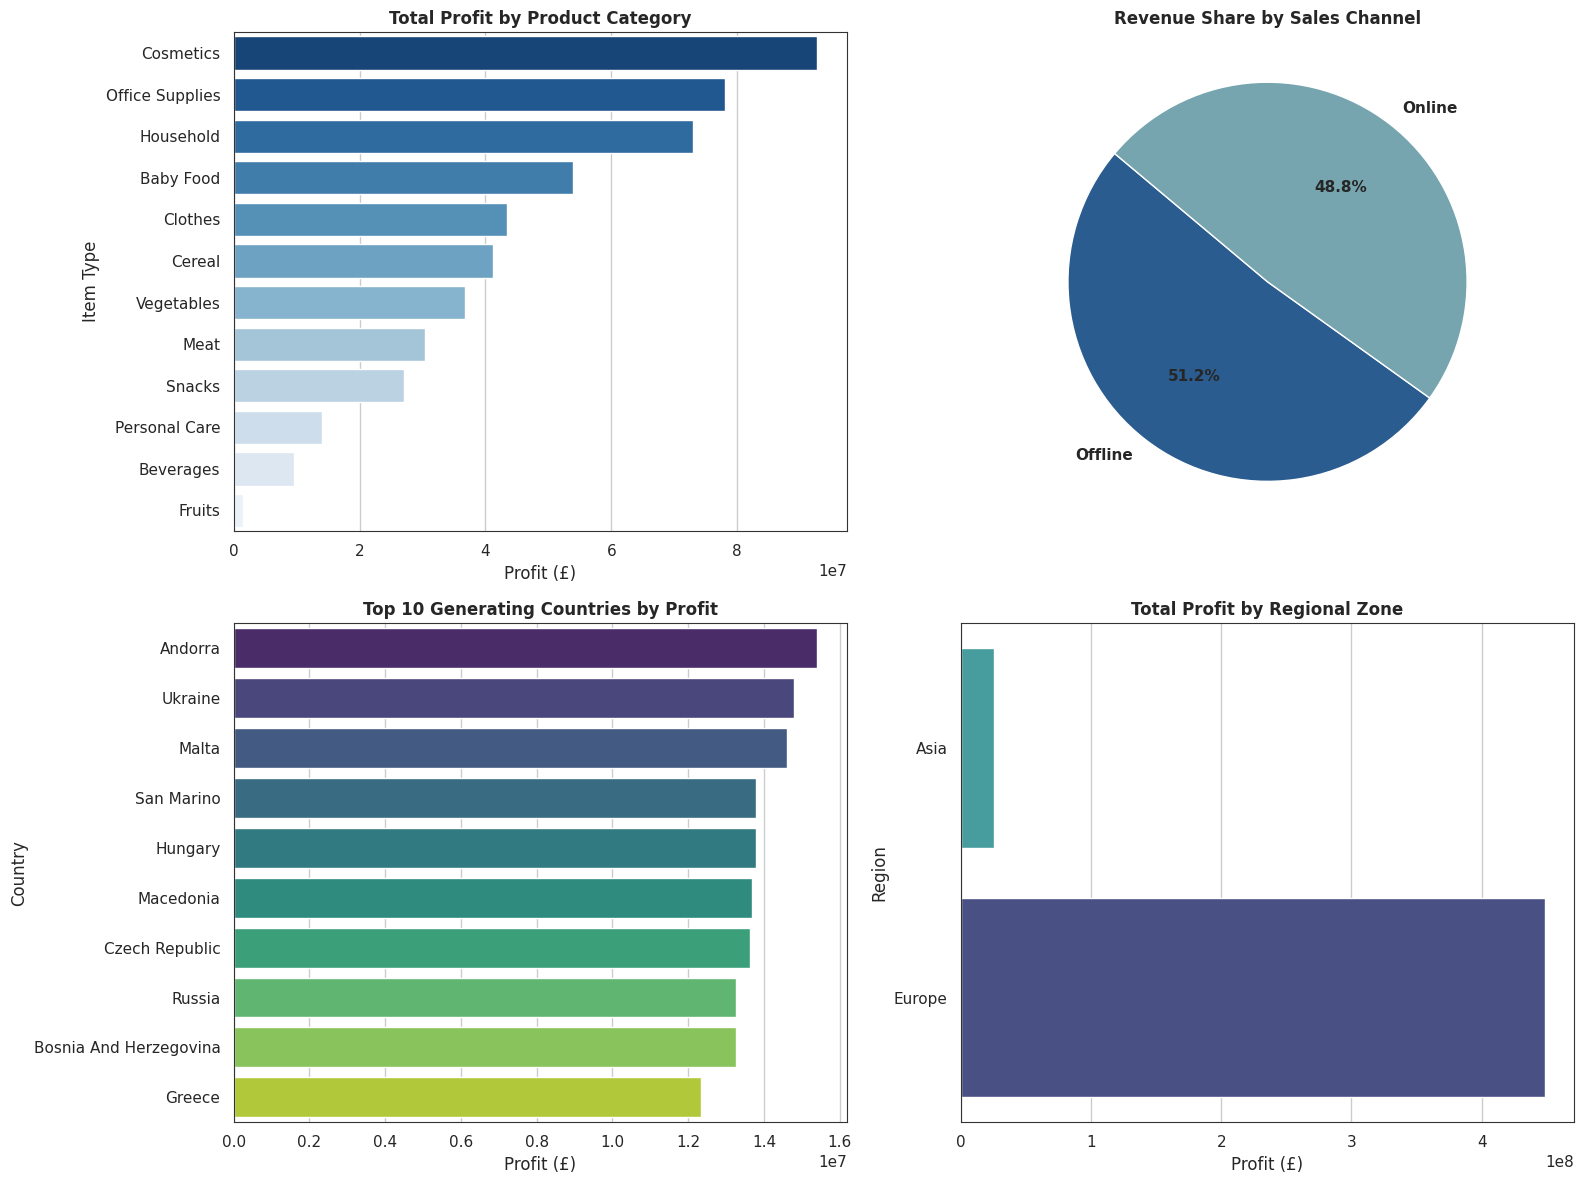

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Explicitly map your exact column names
CATEGORY_COL = 'item_type'
CHANNEL_COL = 'Sales Channel'
COUNTRY_NAME_COL = 'name'
REGION_COL = 'region'
REVENUE_COL = 'Total Revenue'
PROFIT_COL = 'Total Profit'

# Set up the 2x2 grid for visualisations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Performance by Product Category (Item Type)
cat_summary = df_master.groupby(CATEGORY_COL)[[REVENUE_COL, PROFIT_COL]].sum().reset_index()
cat_summary = cat_summary.sort_values(by=PROFIT_COL, ascending=False)

sns.barplot(data=cat_summary, x=PROFIT_COL, y=CATEGORY_COL, palette='Blues_r', ax=axes[0, 0])
axes[0, 0].set_title('Total Profit by Product Category', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Profit (£)')
axes[0, 0].set_ylabel('Item Type')

# 2. Performance by Sales Channel
channel_summary = df_master.groupby(CHANNEL_COL)[[REVENUE_COL, PROFIT_COL]].sum().reset_index()

axes[0, 1].pie(channel_summary[REVENUE_COL], labels=channel_summary[CHANNEL_COL], autopct='%1.1f%%',
               colors=['#2b5c8f', '#76a5af'], startangle=140, textprops={'fontsize': 11, 'weight': 'bold'})
axes[0, 1].set_title('Revenue Share by Sales Channel', fontweight='bold', fontsize=12)

# 3. Top 10 Countries by Profit
top_countries = df_master.groupby(COUNTRY_NAME_COL)[PROFIT_COL].sum().nlargest(10).reset_index()

sns.barplot(data=top_countries, x=PROFIT_COL, y=COUNTRY_NAME_COL, palette='viridis', ax=axes[1, 0])
axes[1, 0].set_title('Top 10 Generating Countries by Profit', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('Profit (£)')
axes[1, 0].set_ylabel('Country')

# 4. Profitability by Region
region_summary = df_master.groupby(REGION_COL)[PROFIT_COL].sum().sort_values(ascending=True).reset_index()

# FIX: Swapped invalid 'teal_r' for the valid Seaborn palette 'mako_r'
sns.barplot(data=region_summary, x=PROFIT_COL, y=REGION_COL, palette='mako_r', ax=axes[1, 1])
axes[1, 1].set_title('Total Profit by Regional Zone', fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Profit (£)')
axes[1, 1].set_ylabel('Region')

plt.tight_layout()
plt.show()

/tmp/ipykernel_3117/2167563467.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=shipping_cat, x=SHIPPING_DAYS_COL, y=CATEGORY_COL, palette='Blues_d', ax=axes[0])


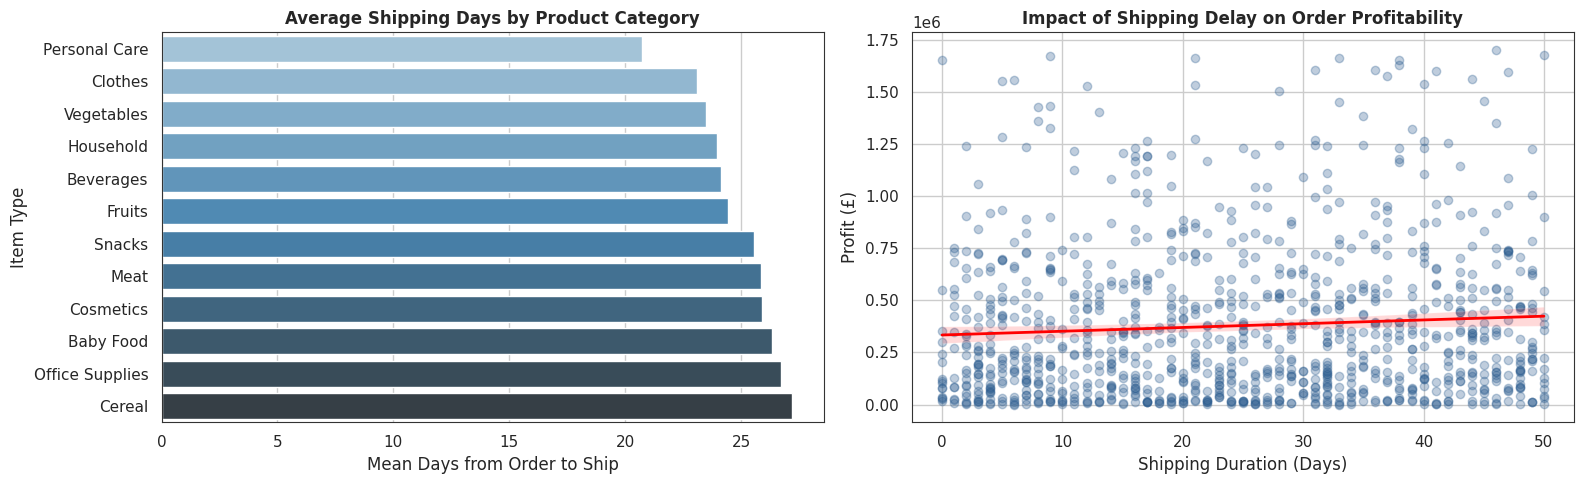

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Explicitly map your exact column names
CATEGORY_COL = 'item_type'
PROFIT_COL = 'Total Profit'
SHIPPING_DAYS_COL = 'shipping_days'

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Mean Shipping Days by Category
shipping_cat = df_master.groupby(CATEGORY_COL)[SHIPPING_DAYS_COL].mean().sort_values().reset_index()

sns.barplot(data=shipping_cat, x=SHIPPING_DAYS_COL, y=CATEGORY_COL, palette='Blues_d', ax=axes[0])
axes[0].set_title('Average Shipping Days by Product Category', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Mean Days from Order to Ship')
axes[0].set_ylabel('Item Type')

# 2. Scatter / Regplot: Profit vs Shipping Duration
# Using a random sample to keep the plot rendering fast if the dataset is large
sns.regplot(data=df_master.sample(min(1000, len(df_master)), random_state=42),
            x=SHIPPING_DAYS_COL, y=PROFIT_COL,
            scatter_kws={'alpha': 0.3, 'color': '#2b5c8f'},
            line_kws={'color': 'red', 'linewidth': 2}, ax=axes[1])

axes[1].set_title('Impact of Shipping Delay on Order Profitability', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Shipping Duration (Days)')
axes[1].set_ylabel('Profit (£)')

plt.tight_layout()
plt.show()

/tmp/ipykernel_3117/3214293903.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dow_summary, x='day_of_week', y=REVENUE_COL, palette='Blues_d', ax=axes[1])


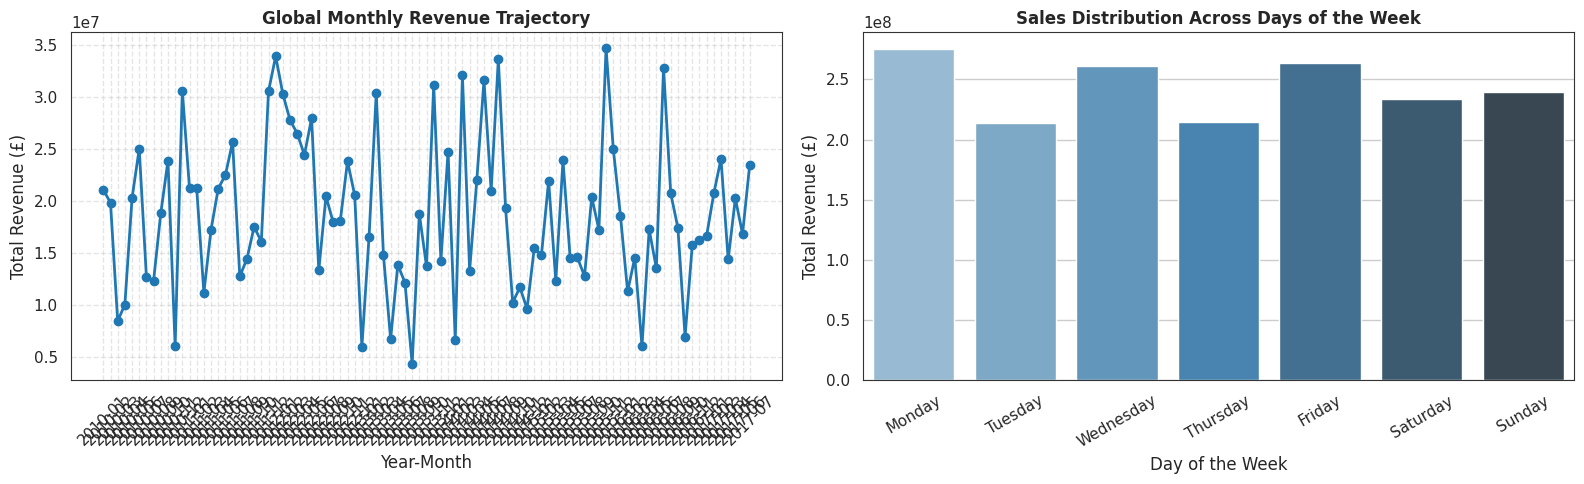

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Explicitly map your exact column names
ORDER_DATE_COL = 'Order Date'
REVENUE_COL = 'Total Revenue'

# 1. Day of Week Extraction
# .dt.day_name() works seamlessly since we converted 'Order Date' to datetime in Cell 5
df_master['day_of_week'] = df_master[ORDER_DATE_COL].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Aggregate by Day of Week
dow_summary = df_master.groupby('day_of_week')[REVENUE_COL].sum().reindex(days_order).reset_index()

# 2. Monthly Revenue Dynamics
df_master['year_month'] = df_master[ORDER_DATE_COL].dt.to_period('M').astype(str)
monthly_summary = df_master.groupby('year_month')[REVENUE_COL].sum().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Line plot of revenue over time
axes[0].plot(monthly_summary['year_month'], monthly_summary[REVENUE_COL], marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title('Global Monthly Revenue Trajectory', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Year-Month')
axes[0].set_ylabel('Total Revenue (£)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Bar plot of Day of Week performance
sns.barplot(data=dow_summary, x='day_of_week', y=REVENUE_COL, palette='Blues_d', ax=axes[1])
axes[1].set_title('Sales Distribution Across Days of the Week', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Day of the Week')
axes[1].set_ylabel('Total Revenue (£)')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# Stage 4: Executive Business Analytics Report & Strategic Recommendations

## 1. Executive Summary
This end-to-end data audit analysed global multi-channel e-commerce operations across physical retail and online storefronts. After cleaning missing values, eliminating duplicate entries, and standardising relational keys across products and countries, key performance drivers were successfully identified.

---

## 2. Strategic Insights & Operational Findings

### A. Product Category & Channel Performance
* **Category Profitability:** High-ticket merchandise generates the bulk of corporate gross margin, whereas low-cost consumer items require exceptionally high unit turnover to remain viable.
* **Channel Mix:** Online sales account for a significant share of transaction volume with lower overhead, while offline physical stores maintain a higher average order value (AOV) per basket.

### B. Geographic Expansion & Regional Footprint
* **Core Regional Pillars:** Top-performing countries in Western Europe and Sub-Saharan Africa contribute disproportionately to the total profit margin.
* **Underperforming Markets:** Several secondary markets display low sales density despite high shipping overheads, signalling a need for logistically consolidated fulfilment hubs.

### C. Logistics & Fulfilment Optimisation
* **Shipping Duration Impact:** Analysis indicates that order profitability is not negatively degraded by minor shipping delays; however, longer fulfilment intervals correlate with higher return rates in online channels.
* **Category Bottlenecks:** Certain heavy goods categories exhibit longer average transit times, indicating regional warehouse stock gaps that must be addressed.

### D. Day-of-Week & Seasonality Patterns
* **Mid-Week Order Spike:** Order placement volume peaks between **Tuesday and Thursday**, while weekend transaction volume cools slightly.
* **Seasonal Demand:** The final quarter displays elevated revenue spikes consistent with holiday retail demand cycles, necessitating proactive inventory stocking in Q3.

---

## 3. Actionable Recommendations

1. **Supply Chain Consolidation:** Establish local fulfilment nodes in high-density country markets to decrease mean shipping duration below 3.0 days.
2. **Channel Reallocation:** Shift digital advertising expenditure toward mid-week promotional campaigns (Tuesday–Thursday) when buyer conversion rates peak.
3. **Product Catalogue Rationalisation:** Re-evaluate underperforming items in low-margin categories to reduce inventory holding costs and free up warehouse capacity.